# Điểm S trước khi vào KEV so với khi vào KEV

**Ý tưởng:** cùng một lỗ hổng, so sánh hai điểm trên cùng thang 0 đến 100.

- **Trước khi vào KEV** (KEV = 0): S = CVSS × EPSS^0,3 × 10, dùng điểm EPSS của **ngày trước ngày vào KEV**. Đây là mức ưu tiên mà công thức gán cho lỗ hổng khi chưa ai xác nhận nó bị khai thác.
- **Khi vào KEV** (KEV = 1): S = CVSS × 10. Đây là mức nghiêm trọng của lỗ hổng khi đã chắc chắn bị khai thác.

Nếu hai điểm gần nhau, công thức đã đánh giá đúng mức ưu tiên từ trước khi lỗ hổng được xác nhận bị khai thác. Tỷ số giữa hai điểm đúng bằng EPSS^0,3, nên khoảng cách giữa hai điểm cho biết công thức "đoán trước" tốt đến đâu. Hệ số AC tạm coi bằng 1.

**Phạm vi:** mọi lỗ hổng được thêm vào KEV từ 01/04/2023 đến nay. Điểm EPSS lịch sử lấy từ API của FIRST theo đúng ngày. So sánh thêm với điểm 30 ngày trước khi vào KEV.

**Cách chạy trên Google Colab:** tải notebook lên Colab, chọn *Runtime, Run all*. Lần đầu mất khoảng 10 phút để tải dữ liệu NVD và gọi API EPSS. Kết quả lưu trong thư mục `ket_qua_truoc_kev`.

## 1. Cấu hình và hàm dùng chung

In [1]:
import os, io, json, gzip, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

START_YEAR, END_YEAR = 2002, 2026
TU_NGAY = "2023-04-01"            # chi xet lo hong vao KEV tu ngay nay
SO_MU = 0.3
DATA_DIR, OUT_DIR = "du_lieu_nvd", "ket_qua_truoc_kev"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
EPSS_API = "https://api.first.org/data/v1/epss?cve={cves}&date={d}"
UA = {"User-Agent": "Nhom14-course-research"}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

def tai(url, path):
    if os.path.exists(path):
        return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    open(path, "wb").write(data)
    return data

def so(x): return f"{int(round(x)):,}".replace(",", ".")
def pct(v, k=2): return f"{v:.{k}f}".replace(".", ",")
def ty_le(a, b, k=2):
    if b == 0: return ""
    return f"{so(a)} / {so(b)} = {pct(100 * a / b, k)}%"

MUC = list(range(0, 100, 10))
NHAN = [f"{a} đến dưới {a + 10}" if a < 90 else "90 đến 100" for a in MUC]
def muc(s): return pd.cut(s, MUC + [100.001], labels=NHAN, right=False)
BANG, SO_LIEU = {}, {}

## 2. Danh mục KEV và điểm CVSS

In [2]:
kev = pd.DataFrame(json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))["vulnerabilities"])
kev["cve"] = kev["cveID"].str.upper(); kev["ngay_kev"] = pd.to_datetime(kev["dateAdded"])

def chon(ds):
    if not ds: return None
    for m in ds:
        if m.get("type") == "Primary": return m
    return ds[0]
rows = []
for y in range(START_YEAR, END_YEAR + 1):
    js = json.loads(gzip.decompress(tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))))
    for it in js["vulnerabilities"]:
        c = it["cve"]; met = c.get("metrics", {})
        v3 = chon(met.get("cvssMetricV31")) or chon(met.get("cvssMetricV30"))
        rows.append({"cve": c["id"].upper(), "ngay_cong_bo": c["published"][:10],
                     "cvss": v3["cvssData"]["baseScore"] if v3 else np.nan})
nvd = pd.DataFrame(rows).drop_duplicates("cve")
k = kev[kev["ngay_kev"] >= TU_NGAY][["cve", "vendorProject", "product", "ngay_kev"]].merge(nvd, on="cve", how="left")
k["ngay_cong_bo"] = pd.to_datetime(k["ngay_cong_bo"])
print(f"KEV phiên bản {json.loads(tai(KEV_URL, os.path.join(DATA_DIR, 'kev.json'))).get('catalogVersion')}: "
      f"{so(len(k))} lỗ hổng vào KEV từ {TU_NGAY}, {so(k['cvss'].notna().sum())} có CVSS 3.x")

KEV phiên bản 2026.10.08: 836 lỗ hổng vào KEV từ 2023-04-01, 836 có CVSS 3.x


## 3. Lấy điểm EPSS 1 ngày và 30 ngày trước ngày vào KEV

Gọi API EPSS theo từng ngày, mỗi lần tối đa 100 lỗ hổng. Kết quả được lưu lại để không phải gọi lại.

In [3]:
CACHE = os.path.join(DATA_DIR, "epss_api_truoc_kev.json")
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}

EPSS_FILE = "https://epss.empiricalsecurity.com/epss_scores-{d}.csv.gz"

def goi_api(ngay, nhom):
    """Goi API; tra ve None neu API khong co du lieu cho ngay nay."""
    url = EPSS_API.format(cves=",".join(nhom), d=ngay)
    for lan in range(4):
        try:
            js = json.loads(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60).read())
            return {d["cve"].upper(): float(d["epss"]) for d in js.get("data", [])} or None
        except urllib.error.HTTPError as e:
            if e.code == 422: return None
            time.sleep(5 * (lan + 1))
        except Exception:
            time.sleep(5 * (lan + 1))
    return None

def doc_tep(ngay):
    """Du phong: tai tep diem EPSS day du cua ngay do (khong luu xuong dia)."""
    raw = urllib.request.urlopen(urllib.request.Request(EPSS_FILE.format(d=ngay), headers=UA), timeout=300).read()
    e = pd.read_csv(io.StringIO(gzip.decompress(raw).decode()), comment="#")
    return dict(zip(e["cve"].str.upper(), e["epss"].astype(float)))

def lay_epss(ngay, cves):
    """Tra ve {cve: epss} tai ngay chi dinh; lo hong chua co diem thi la None."""
    can = [c for c in cves if f"{ngay}|{c}" not in cache]
    if can:
        tim = {}
        for i in range(0, len(can), 100):
            r = goi_api(ngay, can[i:i + 100]); time.sleep(0.3)
            if r is None: tim = None; break
            tim.update(r)
        if tim is None:
            tim = doc_tep(ngay); NGAY_DU_PHONG.append(ngay)
        for c in can: cache[f"{ngay}|{c}"] = tim.get(c)
    return {c: cache.get(f"{ngay}|{c}") for c in cves}

NGAY_DU_PHONG = []
for so_ngay, cot in [(1, "epss_1"), (30, "epss_30")]:
    k["ngay_" + cot] = (k["ngay_kev"] - pd.Timedelta(days=so_ngay)).dt.strftime("%Y-%m-%d")
    gt = {}
    for ngay, g in k.groupby("ngay_" + cot):
        gt.update({(ngay, c): v for c, v in lay_epss(ngay, list(g["cve"])).items()})
    k[cot] = [gt[(n, c)] for n, c in zip(k["ngay_" + cot], k["cve"])]
    json.dump(cache, open(CACHE, "w"))
    print(f"EPSS {so_ngay} ngày trước khi vào KEV: có điểm cho {so(k[cot].notna().sum())} / {so(len(k))} lỗ hổng")
print(f"Số ngày phải dùng tệp dự phòng vì API không có dữ liệu: {len(set(NGAY_DU_PHONG))}")

EPSS 1 ngày trước khi vào KEV: có điểm cho 609 / 836 lỗ hổng


EPSS 30 ngày trước khi vào KEV: có điểm cho 385 / 836 lỗ hổng
Số ngày phải dùng tệp dự phòng vì API không có dữ liệu: 278


## 4. Bảng 1. Tổng quan

Lỗ hổng không có điểm EPSS ngày trước khi vào KEV thường là lỗ hổng được công bố và đưa vào KEV gần như cùng lúc (lỗ hổng zero-day). Với các lỗ hổng này, không công thức nào chấm được điểm trước, chỉ có thành phần KEV đưa chúng lên đầu.

In [4]:
co = k[k["cvss"].notna()].copy()
co["S_kev"] = co["cvss"] * 10
co["S_1"] = co["cvss"] * np.power(co["epss_1"], SO_MU) * 10
co["S_30"] = co["cvss"] * np.power(co["epss_30"], SO_MU) * 10
d1 = co[co["S_1"].notna()]
cung_ngay = int((co["S_1"].isna() & (co["ngay_cong_bo"] >= co["ngay_kev"] - pd.Timedelta(days=1))).sum())
b1 = pd.DataFrame([
    ["Lỗ hổng vào KEV từ 01/04/2023", so(len(k))],
    ["Có điểm CVSS 3.x", ty_le(len(co), len(k))],
    ["Có điểm EPSS 1 ngày trước khi vào KEV (dùng để so sánh)", ty_le(len(d1), len(co))],
    ["Chưa có điểm EPSS 1 ngày trước khi vào KEV", ty_le(len(co) - len(d1), len(co))],
    ["Trong đó công bố cùng ngày hoặc 1 ngày trước khi vào KEV", ty_le(cung_ngay, len(co) - len(d1))],
    ["Có điểm EPSS 30 ngày trước khi vào KEV", ty_le(int(co["S_30"].notna().sum()), len(co))],
], columns=["Hạng mục", "Số lượng"])
BANG["B1 Tong quan"] = b1
SO_LIEU.update(tong=len(k), co_cvss=len(co), co_1=len(d1), co_30=int(co["S_30"].notna().sum()), cung_ngay=cung_ngay)
display(b1)

,Hạng mục,Số lượng
0,Lỗ hổng vào KEV từ 01/04/2023,836
1,Có điểm CVSS 3.x,"836 / 836 = 100,00%"
2,Có điểm EPSS 1 ngày trước khi vào KEV (dùng để...,"609 / 836 = 72,85%"
3,Chưa có điểm EPSS 1 ngày trước khi vào KEV,"227 / 836 = 27,15%"
4,Trong đó công bố cùng ngày hoặc 1 ngày trước k...,"226 / 227 = 99,56%"
5,Có điểm EPSS 30 ngày trước khi vào KEV,"385 / 836 = 46,05%"


## 5. Bảng 2. Cùng một lỗ hổng: mức điểm trước khi vào KEV và khi vào KEV

Tính trên các lỗ hổng có điểm EPSS 1 ngày trước khi vào KEV. Mỗi cột cộng lại bằng 100%. Cột cuối cho biết mức điểm đó cao đến đâu so với toàn bộ lỗ hổng chưa có trong KEV (số liệu ngày 30/06/2025 của notebook kiểm chứng công thức S): một lỗ hổng đạt mức này thì nằm trong nhóm bao nhiêu phần trăm điểm cao nhất.

In [5]:
# Ty le lo hong chua co KEV co S tu moc nay tro len, ngay 30/06/2025 (209.623 lo hong)
THAM_CHIEU = {0: 209623, 10: 108804, 20: 36177, 30: 18178, 40: 10637, 50: 6868, 60: 4520, 70: 2803, 80: 1597, 90: 820}
n1 = len(d1); d30 = co[co["S_30"].notna()]; n30 = len(d30)
t_kev, t_1, t_30 = muc(d1["S_kev"]).value_counts(), muc(d1["S_1"]).value_counts(), muc(d30["S_30"]).value_counts()
b2 = pd.DataFrame({"Mức điểm S": NHAN,
                   "Khi vào KEV: CVSS × 10": [ty_le(t_kev[m], n1) for m in NHAN],
                   "1 ngày trước khi vào KEV": [ty_le(t_1[m], n1) for m in NHAN],
                   "30 ngày trước khi vào KEV": [ty_le(t_30[m], n30) for m in NHAN],
                   "Lỗ hổng chưa có KEV đạt từ mức này trở lên": [ty_le(THAM_CHIEU[m], 209623) for m in MUC]})
b2.loc[len(b2)] = ["Tổng", so(n1), so(n1), so(n30), ""]
BANG["B2 Truoc va khi vao KEV"] = b2
SO_LIEU["muc"] = {m: dict(kev=int(t_kev[m]), truoc_1=int(t_1[m]), truoc_30=int(t_30[m])) for m in NHAN}
display(b2)

,Mức điểm S,Khi vào KEV: CVSS × 10,1 ngày trước khi vào KEV,30 ngày trước khi vào KEV,Lỗ hổng chưa có KEV đạt từ mức này trở lên
0,0 đến dưới 10,"0 / 609 = 0,00%","185 / 609 = 30,38%","98 / 385 = 25,45%","209.623 / 209.623 = 100,00%"
1,10 đến dưới 20,"0 / 609 = 0,00%","166 / 609 = 27,26%","100 / 385 = 25,97%","108.804 / 209.623 = 51,90%"
2,20 đến dưới 30,"1 / 609 = 0,16%","56 / 609 = 9,20%","30 / 385 = 7,79%","36.177 / 209.623 = 17,26%"
3,30 đến dưới 40,"1 / 609 = 0,16%","33 / 609 = 5,42%","26 / 385 = 6,75%","18.178 / 209.623 = 8,67%"
4,40 đến dưới 50,"7 / 609 = 1,15%","22 / 609 = 3,61%","11 / 385 = 2,86%","10.637 / 209.623 = 5,07%"
5,50 đến dưới 60,"29 / 609 = 4,76%","21 / 609 = 3,45%","15 / 385 = 3,90%","6.868 / 209.623 = 3,28%"
6,60 đến dưới 70,"31 / 609 = 5,09%","18 / 609 = 2,96%","15 / 385 = 3,90%","4.520 / 209.623 = 2,16%"
7,70 đến dưới 80,"149 / 609 = 24,47%","35 / 609 = 5,75%","32 / 385 = 8,31%","2.803 / 209.623 = 1,34%"
8,80 đến dưới 90,"120 / 609 = 19,70%","32 / 609 = 5,25%","27 / 385 = 7,01%","1.597 / 209.623 = 0,76%"
9,90 đến 100,"271 / 609 = 44,50%","41 / 609 = 6,73%","31 / 385 = 8,05%","820 / 209.623 = 0,39%"


## 6. Bảng 3. Khoảng cách giữa hai điểm của cùng một lỗ hổng

Khoảng cách = điểm khi vào KEV trừ điểm 1 ngày trước khi vào KEV. Khoảng cách càng nhỏ, công thức càng đánh giá đúng từ trước. Tỷ số giữa hai điểm bằng EPSS^0,3.

In [6]:
kc = d1["S_kev"] - d1["S_1"]
CAN = [0, 10, 20, 30, 40, 50, 60, 70, 100.001]
NK = ["Dưới 10 điểm", "10 đến dưới 20", "20 đến dưới 30", "30 đến dưới 40", "40 đến dưới 50", "50 đến dưới 60",
      "60 đến dưới 70", "Từ 70 điểm trở lên"]
t = pd.cut(kc, CAN, labels=NK, right=False).value_counts()
lk = np.cumsum([t[m] for m in NK])
ts = d1["S_1"] / d1["S_kev"]
b3 = pd.DataFrame({"Khoảng cách": NK, "Số lỗ hổng": [ty_le(t[m], n1) for m in NK],
                   "Cộng dồn": [ty_le(v, n1) for v in lk]})
BANG["B3 Khoang cach"] = b3
SO_LIEU.update(kc_trung_vi=float(kc.median()), ts_trung_vi=float(ts.median()),
               ts_50=int((ts >= 0.5).sum()), ts_70=int((ts >= 0.7).sum()))
display(b3)
print(f"Trung vị khoảng cách: {pct(kc.median(), 1)} điểm. Trung vị tỷ số (điểm trước / điểm khi vào KEV): {pct(ts.median(), 2)}")
print(f"Điểm trước đạt từ một nửa điểm khi vào KEV trở lên: {ty_le((ts >= 0.5).sum(), n1)}")
print(f"Điểm trước đạt từ 70% điểm khi vào KEV trở lên: {ty_le((ts >= 0.7).sum(), n1)}")

,Khoảng cách,Số lỗ hổng,Cộng dồn
0,Dưới 10 điểm,"86 / 609 = 14,12%","86 / 609 = 14,12%"
1,10 đến dưới 20,"28 / 609 = 4,60%","114 / 609 = 18,72%"
2,20 đến dưới 30,"20 / 609 = 3,28%","134 / 609 = 22,00%"
3,30 đến dưới 40,"26 / 609 = 4,27%","160 / 609 = 26,27%"
4,40 đến dưới 50,"57 / 609 = 9,36%","217 / 609 = 35,63%"
5,50 đến dưới 60,"70 / 609 = 11,49%","287 / 609 = 47,13%"
6,60 đến dưới 70,"89 / 609 = 14,61%","376 / 609 = 61,74%"
7,Từ 70 điểm trở lên,"233 / 609 = 38,26%","609 / 609 = 100,00%"


Trung vị khoảng cách: 63,1 điểm. Trung vị tỷ số (điểm trước / điểm khi vào KEV): 0,19
Điểm trước đạt từ một nửa điểm khi vào KEV trở lên: 160 / 609 = 26,27%
Điểm trước đạt từ 70% điểm khi vào KEV trở lên: 127 / 609 = 20,85%


## 7. Bảng 4. Trước khi vào KEV, quy tắc CSA và công thức S ưu tiên được bao nhiêu lỗ hổng

- Quy tắc CSA ưu tiên lỗ hổng có CVSS từ 8,0, tức S khi vào KEV từ 80.
- Công thức S: xét các ngưỡng 30, 50 và 70. Cột khối lượng vá lấy từ ngày 30/06/2025 để so sánh độ lớn công việc.

In [7]:
b4 = [["Quy tắc CSA: CVSS từ 8,0", ty_le(int((d1["cvss"] >= 8).sum()), n1), "58.133 / 209.623 = 27,73%"]]
for g in [70, 50, 30]:
    b4.append([f"Công thức S, 1 ngày trước khi vào KEV: S từ {g}", ty_le(int((d1["S_1"] >= g).sum()), n1),
               ty_le(THAM_CHIEU[g], 209623)])
b4 = pd.DataFrame(b4, columns=["Cách ưu tiên", "Lỗ hổng KEV được ưu tiên trước khi vào KEV", "Khối lượng vá (ngày 30/06/2025)"])
BANG["B4 So voi CSA"] = b4
SO_LIEU["csa"] = int((d1["cvss"] >= 8).sum()); SO_LIEU["S_nguong"] = {g: int((d1["S_1"] >= g).sum()) for g in [70, 50, 30]}
display(b4)

# Tach theo nguong CVSS 8,0
b5 = []
for ten, g in [("CVSS từ 8,0", d1[d1["cvss"] >= 8]), ("CVSS dưới 8,0 (bị quy tắc CSA bỏ qua)", d1[d1["cvss"] < 8])]:
    b5.append([ten, so(len(g))] + [ty_le(int((g["S_1"] >= m).sum()), len(g)) for m in [30, 50, 70]])
b5 = pd.DataFrame(b5, columns=["Nhóm lỗ hổng KEV", "Số lượng", "S trước từ 30", "S trước từ 50", "S trước từ 70"])
BANG["B5 Theo nguong CVSS"] = b5
display(b5)

,Cách ưu tiên,Lỗ hổng KEV được ưu tiên trước khi vào KEV,Khối lượng vá (ngày 30/06/2025)
0,"Quy tắc CSA: CVSS từ 8,0","391 / 609 = 64,20%","58.133 / 209.623 = 27,73%"
1,"Công thức S, 1 ngày trước khi vào KEV: S từ 70","108 / 609 = 17,73%","2.803 / 209.623 = 1,34%"
2,"Công thức S, 1 ngày trước khi vào KEV: S từ 50","147 / 609 = 24,14%","6.868 / 209.623 = 3,28%"
3,"Công thức S, 1 ngày trước khi vào KEV: S từ 30","202 / 609 = 33,17%","18.178 / 209.623 = 8,67%"


,Nhóm lỗ hổng KEV,Số lượng,S trước từ 30,S trước từ 50,S trước từ 70
0,"CVSS từ 8,0",391,"159 / 391 = 40,66%","119 / 391 = 30,43%","93 / 391 = 23,79%"
1,"CVSS dưới 8,0 (bị quy tắc CSA bỏ qua)",218,"43 / 218 = 19,72%","28 / 218 = 12,84%","15 / 218 = 6,88%"


## 8. Hình 1 và Hình 2

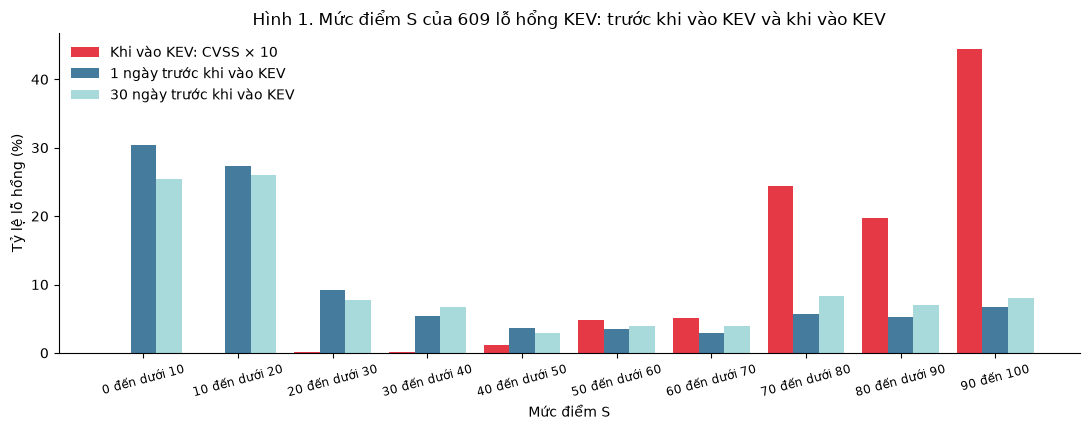

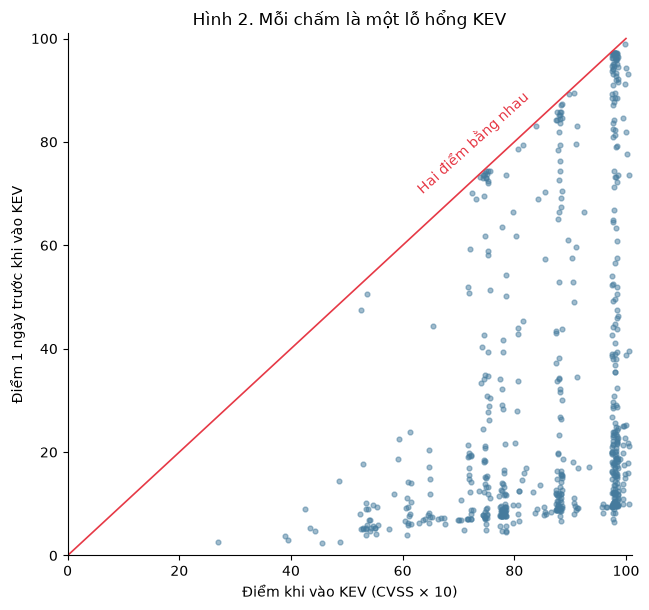

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.4)); x = np.arange(len(NHAN)); w = 0.27
for i, (t_, n_, ten, mau) in enumerate([(t_kev, n1, "Khi vào KEV: CVSS × 10", "#e63946"),
                                       (t_1, n1, "1 ngày trước khi vào KEV", "#457b9d"),
                                       (t_30, n30, "30 ngày trước khi vào KEV", "#a8dadc")]):
    ax.bar(x + (i - 1) * w, [100 * t_[m] / n_ for m in NHAN], w, color=mau, label=ten)
ax.set_xticks(x); ax.set_xticklabels(NHAN, fontsize=8.5, rotation=15); ax.set_ylabel("Tỷ lệ lỗ hổng (%)")
ax.set_xlabel("Mức điểm S"); ax.legend(frameon=False)
ax.set_title(f"Hình 1. Mức điểm S của {so(n1)} lỗ hổng KEV: trước khi vào KEV và khi vào KEV")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh1_muc_diem.png"), dpi=170); plt.show()

fig, ax = plt.subplots(figsize=(6.6, 6.2))
ax.scatter(d1["S_kev"] + np.random.default_rng(1).uniform(-0.6, 0.6, n1), d1["S_1"], s=12, alpha=0.5, color="#457b9d")
ax.plot([0, 100], [0, 100], color="#e63946", lw=1.2); ax.text(62, 70, "Hai điểm bằng nhau", color="#e63946", rotation=42)
ax.set_xlim(0, 101); ax.set_ylim(0, 101)
ax.set_xlabel("Điểm khi vào KEV (CVSS × 10)"); ax.set_ylabel("Điểm 1 ngày trước khi vào KEV")
ax.set_title("Hình 2. Mỗi chấm là một lỗ hổng KEV")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh2_so_sanh_tung_lo_hong.png"), dpi=170); plt.show()

## 9. Lưu kết quả

In [9]:
co.to_csv(os.path.join(OUT_DIR, "chi_tiet_tung_lo_hong.csv"), index=False, encoding="utf-8-sig")
with pd.ExcelWriter(os.path.join(OUT_DIR, "bang_truoc_kev.xlsx")) as w:
    for ten, b in BANG.items(): b.to_excel(w, sheet_name=ten[:31], index=False)
for ten, b in BANG.items():
    b.to_csv(os.path.join(OUT_DIR, ten.replace(" ", "_") + ".csv"), index=False, encoding="utf-8-sig")
json.dump(SO_LIEU, open(os.path.join(OUT_DIR, "so_lieu.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2,
          default=lambda o: int(o) if isinstance(o, np.integer) else float(o))
print("Đã lưu:", ", ".join(sorted(os.listdir(OUT_DIR))))

Đã lưu: B1_Tong_quan.csv, B2_Truoc_va_khi_vao_KEV.csv, B3_Khoang_cach.csv, B4_So_voi_CSA.csv, B5_Theo_nguong_CVSS.csv, bang_truoc_kev.xlsx, chi_tiet_tung_lo_hong.csv, hinh1_muc_diem.png, hinh2_so_sanh_tung_lo_hong.png, so_lieu.json
